## Введение в регрессионный анализ: основной курс
### Задачи для тренировки по итогам недели №2

*Алла Тамбовцева*

**В этих задачах используется тот же массив данных, что и в практикуме 2 (`practice02.ipynb`).**

В файле [SBA_data.csv](https://github.com/allatambov/PyReg26/blob/main/SBA_data.csv) сохранены данные о кредитах, одобренных администрацией по делам малого бизнеса США в 2020 году (фискальный год). Основные переменные:

* `BorrName`: название компании-заемщика;
* `BorrStreet`, `BorrCity`, `BorrState`: адрес, город, штат компании-заемщика;
* `BankName`: название банка, выдающего кредит;
* `BorrStreet`, `BorrCity`, `BorrState`: адрес, город, штат банка;
* `GrossApproval`: сумма кредита, одобренная банком;
* `SBA`: сумма кредита, гарантированная администрацией по делам малого бизнеса (в долларах);
* `InitialInterestRate`: начальная ставка по кредиту;
* `TermInMonths`: срок кредита;
* `LoanOk`: количество одобренных или выплаченных кредитов за предыдущие 10 лет (2010-2019 годы).

Источник оригинальных данных – [Kaggle](https://www.kaggle.com/datasets/thedevastator/sba-loan-guarantee-data-1990-1999), данные были отфильтрованы и преобразованы для задач данного семинара.

Импортируйте необходимые библиотеки и выполните задачи ниже.

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

### Задача 0

Загрузите данные из CSV-файла и сохраните в датафрейм. 

Выберите строки, соответствующие заемщикам, запрашивающим кредит в банках штата Миссури (код `MO` в `BankState`) и сохраните их в датафрейм `mo`. **Дальнейшие задачи нужно выполнять на основе этого датафрейма.**

In [2]:
df = pd.read_csv("SBA_data.csv")
mo = df[df["BankState"] == "MO"]
print(len(mo)) # число строк для проверки

14


### Задача 1

Постройте ковариационную матрицу для переменных `InitialInterestRate` и `LoanOk`. Используя эту матрицу, вычислите коэффициент корреляции Пирсона между выбранными переменными. Проинтерпретируйте полученный результат.

In [3]:
cov_mat = mo[["InitialInterestRate", "LoanOk"]].cov()
cov_mat

,InitialInterestRate,LoanOk
InitialInterestRate,1.059473,-1.609231
LoanOk,-1.609231,4.884615


In [4]:
cov_xy = cov_mat.iloc[0, 1]
var_x = cov_mat.iloc[1, 1]
var_y = cov_mat.iloc[0, 0]

coef =  cov_xy/ np.sqrt(var_x * var_y)
print(coef) # обратная связь, средняя, ближе к сильной

-0.7073889826047305


### Задача 2

Представьте, что вам нужно получить линейную регрессию, описывающую связь между начальной ставкой по кредиту и числом кредитов, одобренных или выплаченных компанией ранее. Какая переменная будет объясняющей, а какая – зависимой?

Используя ковариационную матрицу и описательные статистики подходящих переменных, вычислите оценки коэффициентов модели ($\hat{b}_0$ и $\hat{b}_1$), запишите уравнение регрессии и проинтерпретируйте полученные значения.

In [5]:
# y - LoanOk, x - InterestRate

b1 = cov_xy / var_x
b0 = mo["InitialInterestRate"].mean() - b1 * mo["LoanOk"].mean()
print(b0, b1)

6.198785151856019 -0.32944881889763783


> Уравнение: $\widehat{\text{InterestRate}}_i = 6.2 - 0.33 \times \text{LoanOk}_i$. Если у компании нет в кредитной истории благополучно закрытых кредитов, в среднем, она может ожидать начальную ставку по кредиту в 6.2%. При увеличении числа благополучно закрытых кредитов на 1, начальная ставка по кредиту уменьшается, в среднем, на 0.33 (процентных пункта).

### Задача 3

Используя полученное уравнение модели, вычислите: 

a) предсказанное значение зависимой переменной

b) остаток модели

для компании, имеющей в кредитной истории медианное число одобренных или выплаченных кредитов (медианное – по штату Миссури).

In [6]:
# пункт a
# считаем медиану по столбцу и подставляем в уравнение

x = mo["LoanOk"].median()
yhat = b0 + b1 * x
print(x, yhat)

3.0 5.210438695163106


> Компания, у которой три благополучно закрытых кредита в истории, может ожидать, согласно нашей модели, ставку кредита в 5.21%. 

In [8]:
# пункт b
# нет единого решения, поскольку компания с 3 кредитами не одна,
# выберем какую-нибудь, например первую

mo[mo["LoanOk"] == 3]

,BorrName,BorrStreet,BorrCity,BorrState,BankName,BankStreet,BankCity,BankState,GrossApproval,SBA,ApprovalDate,ApprovalFiscalYear,InitialInterestRate,TermInMonths,LoanOk
136,"Clayton Agri-Marketing, Inc.","3405 West Truman Blvd, Suite 1",JEFFERSON CITY,MO,Commerce Bank,1000 Walnut St,KANSAS CITY,MO,5000000.0,4500000.0,12-19-19,2020,4.19,12,3
170,"Contractor's Engineer, Inc.",7563 Quinter Drive,Neodesha,KS,Commerce Bank,1000 Walnut St,KANSAS CITY,MO,100000.0,85000.0,01-08-20,2020,6.75,3,3
403,"MAGNA TECHNOLOGIES, INC.",40 Downfield Drive,SAINT CHARLES,MO,Enterprise Bank & Trust,150 N Meramec Ave,CLAYTON,MO,925000.0,832500.0,05-21-20,2020,4.75,12,3
404,"MAGNA TECHNOLOGIES, INC.",40 Downfield Drive,SAINT CHARLES,MO,Enterprise Bank & Trust,150 N Meramec Ave,CLAYTON,MO,225000.0,202500.0,05-21-20,2020,4.75,12,3


In [9]:
# x = 3, y = 4.19, yhat = 5.21
# остаток = y - yhat

y = 4.19
print(y - yhat)

-1.0204386951631053


> Для компании Clayton Agri-Marketing, Inc. с тремя благополучными кредитами в истории модель занизила ставку кредита на 1.02 процентных пункта. 

### Задача 4

a) Используя функцию `polyfit()` из `numpy`, получите оценки коэффициентов $\hat{b}_0$ и $\hat{b}_1$. 

b) Постройте диаграмму рассеивания между переменными `LoanOk` и `InitialInterestRate`. Добавьте на нее регрессионную прямую, используя значения из пункта a). 

In [10]:
b1, b0 = np.polyfit(mo["LoanOk"], mo["InitialInterestRate"], deg = 1)
print(b0, b1)

6.198785151856013 -0.3294488188976366


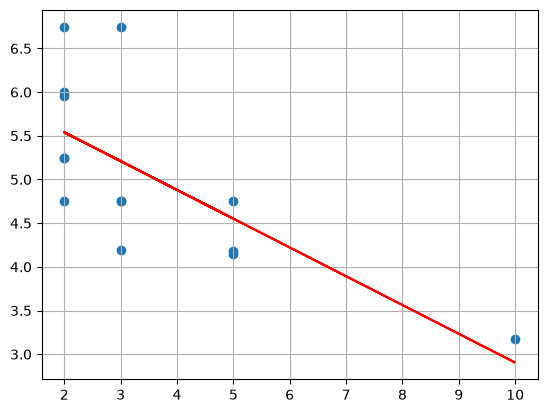

In [11]:
X = mo["LoanOk"]
Y = mo["InitialInterestRate"]
Yhat = b0 + b1 * X

fig, ax = plt.subplots()
ax.scatter(X, Y);
ax.plot(X, Yhat, color = "red");
ax.grid();

### Задача 5

a) Вычислите RSS для построенной линейной регрессионной модели. 

b) Найдите наблюдение с самым большим по модулю остатком. Что это за компания?

In [12]:
# RSS можно найти, не добавляя столбцы в таблицу,
# из предыдущей задачи у нас есть Y и Yhat

Epsilon = Y - Yhat
RSS = (Epsilon ** 2).sum()
print(RSS)

6.881073565804273


In [13]:
# добавляем в таблицу столбец Epsilon

mo["Epsilon"] = Epsilon

In [14]:
# для модуля используем метод .abs(), считаем максимум по столбцу с модулями

max_e = mo["Epsilon"].abs().max()
print(max_e)

1.539561304836897


In [15]:
# находим такую строку в таблице,
# это компания Contractor's Engineer, Inc.

mo[mo["Epsilon"] == max_e]

,BorrName,BorrStreet,BorrCity,BorrState,BankName,BankStreet,BankCity,BankState,GrossApproval,SBA,ApprovalDate,ApprovalFiscalYear,InitialInterestRate,TermInMonths,LoanOk,Epsilon
170,"Contractor's Engineer, Inc.",7563 Quinter Drive,Neodesha,KS,Commerce Bank,1000 Walnut St,KANSAS CITY,MO,100000.0,85000.0,01-08-20,2020,6.75,3,3,1.539561
